# Autoencoder and iForest Anomaly Detection Assignment
**Name:** Chengwei Zhang

## Objectives

This assignment applies unsupervised learning methods to the CMS inpatient charges dataset to identify hospital providers whose billing behavior looks anomalous relative to their peers. The analysis uses two PyOD algorithms, iForest and an Autoencoder, applied to a feature matrix built from the five features created in the previous assignment. For each method, I describe how the algorithm works, run the model, report the size and percentage of flagged records at the provider and DRG level, and interpret what the flagged records reveal about potentially anomalous billing patterns. The final section compares the two methods against each other.

## Section 1: Data Preparation

### Section 1.1: Load Data and Libraries

I begin by importing the necessary libraries and loading the dataset. The PyOD library provides the two anomaly detection algorithms used in this assignment, iForest and an Autoencoder.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pyod.models.combination import aom, moa, average, maximization
from pyod.utils.utility import standardizer
from pyod.models.iforest import IForest
from pyod.models.auto_encoder import AutoEncoder
import torch

torch.manual_seed(42)

In [2]:
data = pd.read_csv('inpatientCharges.csv')
data.head()

,DRG Definition,Provider Id,Provider Name,Provider Street Address,Provider City,Provider State,Provider Zip Code,Hospital Referral Region Description,Total Discharges,Average Covered Charges,Average Total Payments,Average Medicare Payments
0,039 - EXTRACRANIAL PROCEDURES W/O CC/MCC,10001,SOUTHEAST ALABAMA MEDICAL CENTER,1108 ROSS CLARK CIRCLE,DOTHAN,AL,36301,AL - Dothan,91,$32963.07,$5777.24,$4763.73
1,039 - EXTRACRANIAL PROCEDURES W/O CC/MCC,10005,MARSHALL MEDICAL CENTER SOUTH,2505 U S HIGHWAY 431 NORTH,BOAZ,AL,35957,AL - Birmingham,14,$15131.85,$5787.57,$4976.71
2,039 - EXTRACRANIAL PROCEDURES W/O CC/MCC,10006,ELIZA COFFEE MEMORIAL HOSPITAL,205 MARENGO STREET,FLORENCE,AL,35631,AL - Birmingham,24,$37560.37,$5434.95,$4453.79
3,039 - EXTRACRANIAL PROCEDURES W/O CC/MCC,10011,ST VINCENT'S EAST,50 MEDICAL PARK EAST DRIVE,BIRMINGHAM,AL,35235,AL - Birmingham,25,$13998.28,$5417.56,$4129.16
4,039 - EXTRACRANIAL PROCEDURES W/O CC/MCC,10016,SHELBY BAPTIST MEDICAL CENTER,1000 FIRST STREET NORTH,ALABASTER,AL,35007,AL - Birmingham,18,$31633.27,$5658.33,$4851.44


### Section 1.2: Data Preprocessing

Before building the feature matrix, I rename the columns and convert the fields needed for feature reconstruction into the correct data types. The average total payment field is stored as a string with a dollar sign, so I strip out any characters that are not numbers and convert it to a float. This mirrors the preprocessing done in the previous assignment.

In [3]:
# Rename columns
data.columns = ['DRG', 'Provider_Id', 'Provider_Name', 'Provider_StreetAddress', 'Provider_City',
                'Provider_State', 'Provider_Zipcode', 'Hospital_referral_region_desp',
                'Total_Discharges', 'Average_Covered_Charges', 'Average_Total_Payments',
                'Average_Medicare_Payments']

# Convert categorical columns and strip dollar signs from payment amounts to make them numeric
data['DRG'] = data['DRG'].astype('category')
data['Provider_State'] = data['Provider_State'].astype('category')
data['Provider_City'] = data['Provider_City'].astype('category')
data['Provider_Id'] = data['Provider_Id'].astype('category')
data['Average_Total_Payments'] = (data['Average_Total_Payments']
                                   .str.replace(r'[^-+\d.]', '', regex=True).astype(float))

print(f"Dataset shape: {data.shape}")
data.info()

Dataset shape: (163065, 12)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 163065 entries, 0 to 163064
Data columns (total 12 columns):
 #   Column                         Non-Null Count   Dtype   
---  ------                         --------------   -----   
 0   DRG                            163065 non-null  category
 1   Provider_Id                    163065 non-null  category
 2   Provider_Name                  163065 non-null  object  
 3   Provider_StreetAddress         163065 non-null  object  
 4   Provider_City                  163065 non-null  category
 5   Provider_State                 163065 non-null  category
 6   Provider_Zipcode               163065 non-null  int64   
 7   Hospital_referral_region_desp  163065 non-null  object  
 8   Total_Discharges               163065 non-null  int64   
 9   Average_Covered_Charges        163065 non-null  object  
 10  Average_Total_Payments         163065 non-null  float64 
 11  Average_Medicare_Payments      163065 non-null  ob

### Section 1.3: Reconstruct Features from HW3

I reconstruct all five features from the previous assignment and combine them into a single feature matrix. Each feature compares a provider's billing behavior against a peer benchmark, either at the level of state and DRG, the level of region and DRG, or at the provider level across DRGs. Because the underlying billing amounts and discharge counts are always positive, these ratio features do not suffer from the problems caused by dividing by a number close to zero or dividing by a negative number, the artifacts that showed up in the credit card dataset, which will be confirmed later in the feature inspection step.

In [4]:
# Feature 1: Total Payment Ratio by State and DRG

# Compute the average total payment for each group of state and DRG as the peer benchmark
data_fe1 = data.copy()
benchmark1 = data_fe1.groupby(
    ['Provider_State', 'DRG'], observed=True
)['Average_Total_Payments'].mean().reset_index()
benchmark1.columns = ['Provider_State', 'DRG', 'Avg_Total_Payment_ByStateDRG']

# Merge the state and DRG benchmark back to the data at the provider level
data_fe1 = pd.merge(
    data_fe1,
    benchmark1,
    how='left',
    on=['Provider_State', 'DRG']
)

# Compute each provider's total payment ratio relative to the average of its peer group based on state and DRG
data_fe1['total_payment_ratio_state_drg'] = np.where(
    data_fe1['Avg_Total_Payment_ByStateDRG'] == 0,
    0,
    data_fe1['Average_Total_Payments'] / data_fe1['Avg_Total_Payment_ByStateDRG']
)

#### Feature 1 EDA: Distribution of Total Payment Ratio (Mean Based on State and DRG)

This feature compares each provider's average total payment with the mean total payment of hospitals in the same state treating the same DRG. A ratio near 1 means the provider is in line with its peers grouped by state and DRG, and the bulk of records cluster tightly around that point. Because the mean benchmark is sensitive to a small number of hospitals within a group that pay a lot, I carry the ratio based on mean as well as a ratio based on median, computed next as Feature 2, so the two versions of this comparison can be checked against each other.

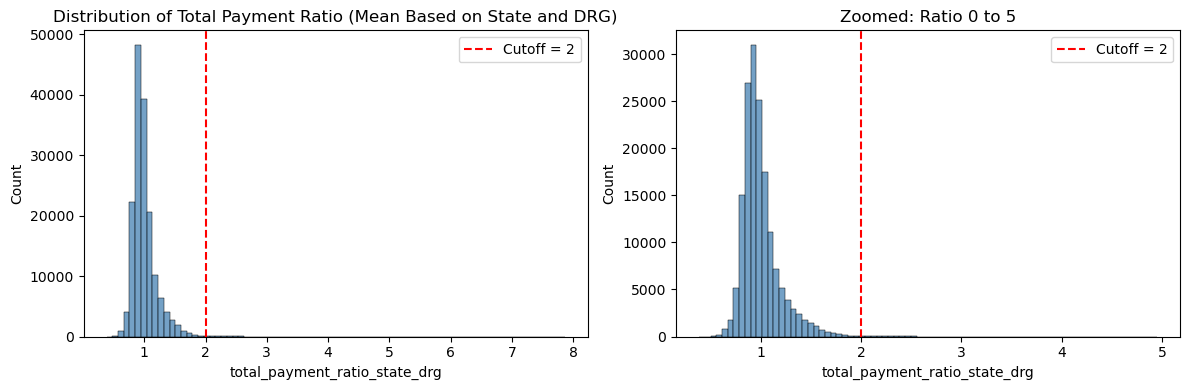

count    163065.000000
mean          1.000000
std           0.195274
min           0.384805
50%           0.956830
90%           1.239137
95%           1.382585
99%           1.662573
max           7.857934
Name: total_payment_ratio_state_drg, dtype: float64


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Full distribution
sns.histplot(data_fe1['total_payment_ratio_state_drg'], bins=80, ax=axes[0], color='steelblue')
axes[0].axvline(2, color='red', linestyle='--', label='Cutoff = 2')
axes[0].set_title('Distribution of Total Payment Ratio (Mean Based on State and DRG)')
axes[0].set_xlabel('total_payment_ratio_state_drg')
axes[0].legend()

# Zoomed to show the bulk of the distribution around the cutoff
zoomed1 = data_fe1[data_fe1['total_payment_ratio_state_drg'] <= 5]
sns.histplot(zoomed1['total_payment_ratio_state_drg'], bins=80, ax=axes[1], color='steelblue')
axes[1].axvline(2, color='red', linestyle='--', label='Cutoff = 2')
axes[1].set_title('Zoomed: Ratio 0 to 5')
axes[1].set_xlabel('total_payment_ratio_state_drg')
axes[1].legend()

plt.tight_layout()
plt.show()

print(data_fe1['total_payment_ratio_state_drg'].describe(percentiles=[0.5, 0.9, 0.95, 0.99]))

In [6]:
# Feature 2: Total Payment Median Ratio by State and DRG

# Compute the median total payment for each group of state and DRG as the peer benchmark
data_fe2 = data.copy()
benchmark2 = data_fe2.groupby(
    ['Provider_State', 'DRG'], observed=True
)['Average_Total_Payments'].median().reset_index()
benchmark2.columns = ['Provider_State', 'DRG', 'Median_Total_Payment_ByStateDRG']

# Merge the state and DRG median benchmark back to the data at the provider level
data_fe2 = pd.merge(
    data_fe2,
    benchmark2,
    how='left',
    on=['Provider_State', 'DRG']
)

# Compute each provider's total payment ratio relative to the median of its peer group based on state and DRG
data_fe2['total_payment_median_ratio_state_drg'] = np.where(
    data_fe2['Median_Total_Payment_ByStateDRG'] == 0,
    0,
    data_fe2['Average_Total_Payments'] / data_fe2['Median_Total_Payment_ByStateDRG']
)

#### Feature 2 EDA: Distribution of Total Payment Ratio (Median Based on State and DRG)

This feature follows the same structure as Feature 1 but uses the median instead of the mean as the peer benchmark. Because total payments are right skewed, a small number of hospitals that pay a lot can pull a group mean upward, which makes the mean a less stable reference point. The median is less affected by that pull, so it gives a steadier picture of what a typical provider in the same state and DRG actually charges, and a high ratio here is a somewhat stronger signal of a real difference than the same ratio computed against the mean.

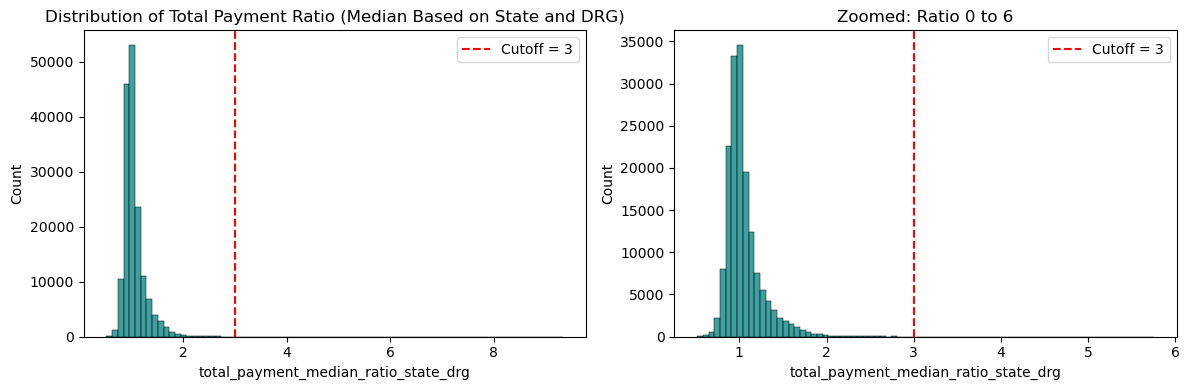

count    163065.000000
mean          1.050746
std           0.211465
min           0.517695
50%           1.000000
90%           1.307567
95%           1.465725
99%           1.790033
max           9.338775
Name: total_payment_median_ratio_state_drg, dtype: float64


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.histplot(data_fe2['total_payment_median_ratio_state_drg'], bins=80, ax=axes[0], color='teal')
axes[0].axvline(3, color='red', linestyle='--', label='Cutoff = 3')
axes[0].set_title('Distribution of Total Payment Ratio (Median Based on State and DRG)')
axes[0].set_xlabel('total_payment_median_ratio_state_drg')
axes[0].legend()

zoomed2 = data_fe2[data_fe2['total_payment_median_ratio_state_drg'] <= 6]
sns.histplot(zoomed2['total_payment_median_ratio_state_drg'], bins=80, ax=axes[1], color='teal')
axes[1].axvline(3, color='red', linestyle='--', label='Cutoff = 3')
axes[1].set_title('Zoomed: Ratio 0 to 6')
axes[1].set_xlabel('total_payment_median_ratio_state_drg')
axes[1].legend()

plt.tight_layout()
plt.show()

print(data_fe2['total_payment_median_ratio_state_drg'].describe(percentiles=[0.5, 0.9, 0.95, 0.99]))

In [8]:
# Feature 3: Discharge Ratio by State and DRG

# Compute the median total discharges for each group of state and DRG as the peer benchmark
data_fe3 = data.copy()
benchmark3 = data_fe3.groupby(
    ['Provider_State', 'DRG'], observed=True
)['Total_Discharges'].median().reset_index()
benchmark3.columns = ['Provider_State', 'DRG', 'Median_Discharge_ByStateDRG']

# Merge the state and DRG discharge benchmark back to the data at the provider level
data_fe3 = pd.merge(
    data_fe3,
    benchmark3,
    how='left',
    on=['Provider_State', 'DRG']
)

# Compute each provider's discharge ratio relative to the median of its peer group based on state and DRG
data_fe3['discharge_median_ratio_state_drg'] = np.where(
    data_fe3['Median_Discharge_ByStateDRG'] == 0,
    0,
    data_fe3['Total_Discharges'] / data_fe3['Median_Discharge_ByStateDRG']
)

#### Feature 3 EDA: Distribution of Discharge Ratio (Median Based on State and DRG)

This feature shifts the focus from payment amounts to patient volume, comparing each provider's total discharges with the median total discharges of hospitals in the same state and DRG. Most providers treat a volume of cases close to their peer median, so the distribution again clusters near 1, but the tail is noticeably wider and longer than the ratios based on payment, which suggests that volume varies more sharply across providers than payment level does for the same case type.

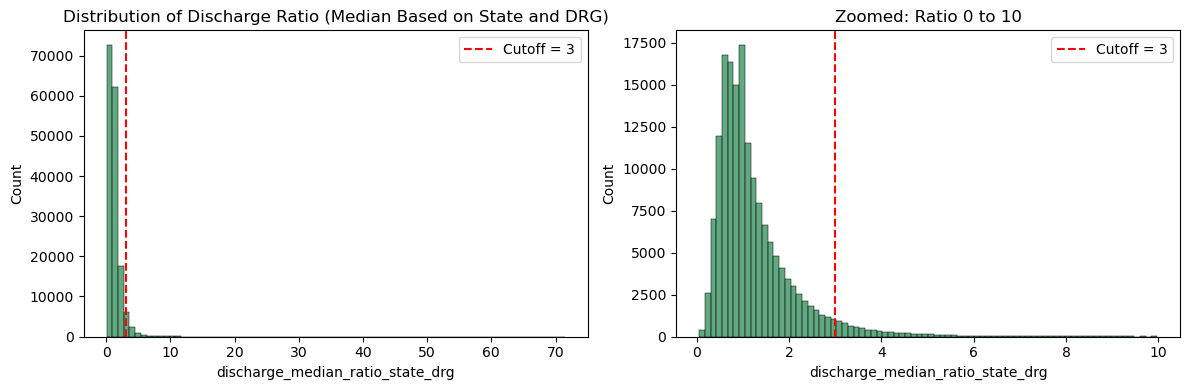

count    163065.000000
mean          1.260075
std           0.987288
min           0.047210
50%           1.000000
90%           2.301887
95%           2.966667
99%           4.816027
max          71.409091
Name: discharge_median_ratio_state_drg, dtype: float64


In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.histplot(data_fe3['discharge_median_ratio_state_drg'], bins=80, ax=axes[0], color='seagreen')
axes[0].axvline(3, color='red', linestyle='--', label='Cutoff = 3')
axes[0].set_title('Distribution of Discharge Ratio (Median Based on State and DRG)')
axes[0].set_xlabel('discharge_median_ratio_state_drg')
axes[0].legend()

zoomed3 = data_fe3[data_fe3['discharge_median_ratio_state_drg'] <= 10]
sns.histplot(zoomed3['discharge_median_ratio_state_drg'], bins=80, ax=axes[1], color='seagreen')
axes[1].axvline(3, color='red', linestyle='--', label='Cutoff = 3')
axes[1].set_title('Zoomed: Ratio 0 to 10')
axes[1].set_xlabel('discharge_median_ratio_state_drg')
axes[1].legend()

plt.tight_layout()
plt.show()

print(data_fe3['discharge_median_ratio_state_drg'].describe(percentiles=[0.5, 0.9, 0.95, 0.99]))

In [10]:
# Feature 4: Total Payment Median Ratio by Hospital Referral Region and DRG

# Compute the median total payment for each group of region and DRG as the peer benchmark
data_fe4 = data.copy()
benchmark4 = data_fe4.groupby(
    ['Hospital_referral_region_desp', 'DRG'], observed=True
)['Average_Total_Payments'].median().reset_index()
benchmark4.columns = ['Hospital_referral_region_desp', 'DRG', 'Median_Total_Payment_ByRegionDRG']

# Merge the region and DRG median benchmark back to the data at the provider level
data_fe4 = pd.merge(
    data_fe4,
    benchmark4,
    how='left',
    on=['Hospital_referral_region_desp', 'DRG']
)

# Compute each provider's total payment ratio relative to the median of its peer group based on region and DRG
data_fe4['total_payment_median_ratio_region_drg'] = np.where(
    data_fe4['Median_Total_Payment_ByRegionDRG'] == 0,
    0,
    data_fe4['Average_Total_Payments'] / data_fe4['Median_Total_Payment_ByRegionDRG']
)

#### Feature 4 EDA: Distribution of Total Payment Ratio (Median Based on Region and DRG)

This feature follows the same structure as Feature 2 but groups providers by hospital referral region instead of state, since patients are sometimes referred across state lines for specialized care. The distribution is very close in shape to Feature 2, with slightly less spread, which suggests that peer groups based on region and peer groups based on state are largely capturing the same geographic cost patterns for most providers.

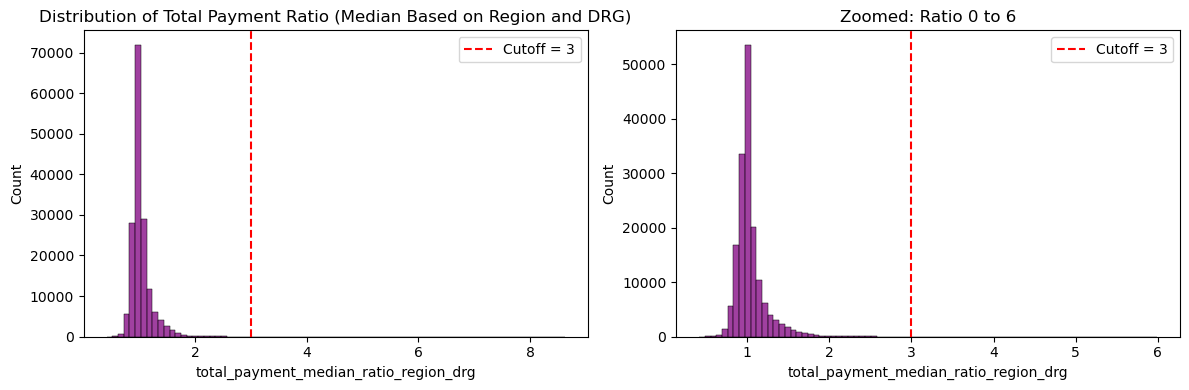

count    163065.000000
mean          1.036331
std           0.179935
min           0.416786
50%           1.000000
90%           1.235917
95%           1.386890
99%           1.682118
max           8.618473
Name: total_payment_median_ratio_region_drg, dtype: float64


In [11]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.histplot(data_fe4['total_payment_median_ratio_region_drg'], bins=80, ax=axes[0], color='purple')
axes[0].axvline(3, color='red', linestyle='--', label='Cutoff = 3')
axes[0].set_title('Distribution of Total Payment Ratio (Median Based on Region and DRG)')
axes[0].set_xlabel('total_payment_median_ratio_region_drg')
axes[0].legend()

zoomed4 = data_fe4[data_fe4['total_payment_median_ratio_region_drg'] <= 6]
sns.histplot(zoomed4['total_payment_median_ratio_region_drg'], bins=80, ax=axes[1], color='purple')
axes[1].axvline(3, color='red', linestyle='--', label='Cutoff = 3')
axes[1].set_title('Zoomed: Ratio 0 to 6')
axes[1].set_xlabel('total_payment_median_ratio_region_drg')
axes[1].legend()

plt.tight_layout()
plt.show()

print(data_fe4['total_payment_median_ratio_region_drg'].describe(percentiles=[0.5, 0.9, 0.95, 0.99]))

In [12]:
# Feature 5: Provider Repeated High Total Payment Count

# Flag each record at the provider and DRG level where the total payment ratio from Feature 1 exceeds 2
data_fe5 = data_fe1.copy()
data_fe5['high_total_payment_flag'] = np.where(
    data_fe5['total_payment_ratio_state_drg'] > 2, 1, 0
)

# Count how many DRG records with high payment each provider has across the dataset
provider_high_payment = data_fe5.groupby(
    ['Provider_Id', 'Provider_Name'], observed=True
)['high_total_payment_flag'].sum().reset_index()
provider_high_payment.columns = ['Provider_Id', 'Provider_Name', 'provider_high_total_payment_count']

# Merge the high payment count at the provider level back to the full data at the provider and DRG level
data_fe5 = pd.merge(
    data_fe5,
    provider_high_payment,
    how='left',
    on=['Provider_Id', 'Provider_Name']
)

#### Feature 5 EDA: Distribution of Repeated High Payment Count

Unlike the first four features, which compare a single record at the provider and DRG level to a peer benchmark, this feature operates at the provider level and counts how many separate DRG categories a provider has already been flagged in under the Feature 1 rule. Most providers are never flagged, so the distribution is heavily concentrated at zero, and a nonzero count is itself informative, since it means the elevated payment pattern is repeating across multiple case types rather than appearing in an isolated record.

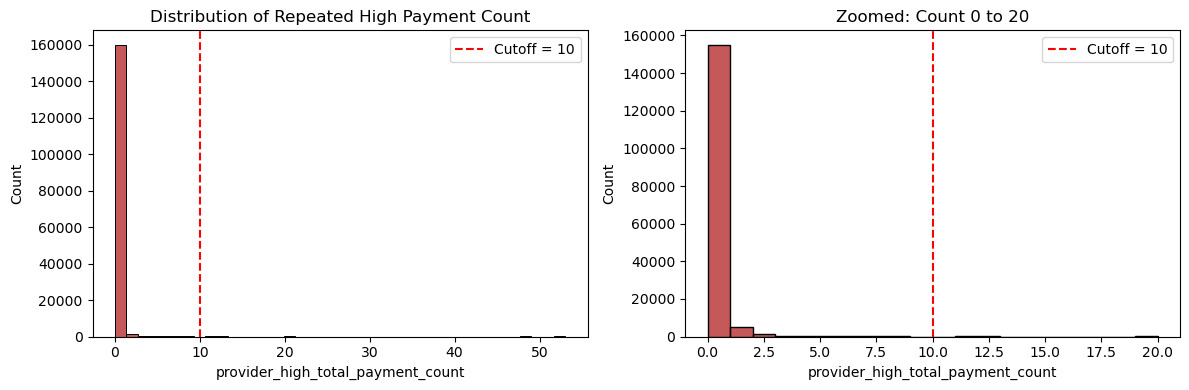

count    163065.000000
mean          0.159439
std           1.784954
min           0.000000
50%           0.000000
90%           0.000000
95%           0.000000
99%           3.000000
max          53.000000
Name: provider_high_total_payment_count, dtype: float64


In [13]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.histplot(data_fe5['provider_high_total_payment_count'], bins=40, ax=axes[0], color='firebrick')
axes[0].axvline(10, color='red', linestyle='--', label='Cutoff = 10')
axes[0].set_title('Distribution of Repeated High Payment Count')
axes[0].set_xlabel('provider_high_total_payment_count')
axes[0].legend()

zoomed5 = data_fe5[data_fe5['provider_high_total_payment_count'] <= 20]
sns.histplot(zoomed5['provider_high_total_payment_count'], bins=20, ax=axes[1], color='firebrick')
axes[1].axvline(10, color='red', linestyle='--', label='Cutoff = 10')
axes[1].set_title('Zoomed: Count 0 to 20')
axes[1].set_xlabel('provider_high_total_payment_count')
axes[1].legend()

plt.tight_layout()
plt.show()

print(data_fe5['provider_high_total_payment_count'].describe(percentiles=[0.5, 0.9, 0.95, 0.99]))

### Section 1.3.5: Feature Inspection and Clipping

Before building the feature matrix, I inspect the summary statistics of all five features to check for unexpected values, following the same practice used in the previous assignment before modeling.

In the credit card dataset, one feature required clipping because some pairs of vendor and category had a negative group average or a group average close to zero, caused by refunds and credits outweighing purchases, which produced ratios in the trillions. That situation does not arise here. The average total payment and total discharge fields in this dataset are billing figures that are always positive, so none of the five ratio or count features can produce the artifacts seen previously that come from dividing by a number close to zero or dividing by a negative number. The maximum values observed below, a payment ratio of under 10 for the four ratio features and a discharge ratio of about 71, are large but reasonable. They reflect providers whose billing or volume really differs from their peer group by ten times or more, not a mistake in the calculation. For this reason, I do not apply clipping to any of the five features before building the feature matrix.

In [14]:
# Inspect summary statistics for all five features before building the feature matrix
feature_preview_cols = [
    'total_payment_ratio_state_drg', 'total_payment_median_ratio_state_drg',
    'discharge_median_ratio_state_drg', 'total_payment_median_ratio_region_drg',
    'provider_high_total_payment_count'
]
preview_df = pd.DataFrame({
    'total_payment_ratio_state_drg': data_fe1['total_payment_ratio_state_drg'],
    'total_payment_median_ratio_state_drg': data_fe2['total_payment_median_ratio_state_drg'],
    'discharge_median_ratio_state_drg': data_fe3['discharge_median_ratio_state_drg'],
    'total_payment_median_ratio_region_drg': data_fe4['total_payment_median_ratio_region_drg'],
    'provider_high_total_payment_count': data_fe5['provider_high_total_payment_count'],
})
print("Summary statistics of raw features:")
print(preview_df.describe().round(2))

# No group averages in this dataset are negative or close to zero (payments and
# discharges are always positive), so no clipping artifacts are present.
print(f"\nMinimum values across features (checking for artifacts):")
print(preview_df.min())

Summary statistics of raw features:
       total_payment_ratio_state_drg  total_payment_median_ratio_state_drg  \
count                      163065.00                             163065.00   
mean                            1.00                                  1.05   
std                             0.20                                  0.21   
min                             0.38                                  0.52   
25%                             0.88                                  0.93   
50%                             0.96                                  1.00   
75%                             1.06                                  1.11   
max                             7.86                                  9.34   

       discharge_median_ratio_state_drg  \
count                         163065.00   
mean                               1.26   
std                                0.99   
min                                0.05   
25%                                0.69   
50%

### Section 1.4: Build Feature Matrix

I combine all five features into a single dataframe at the level of provider and DRG. Features 1 through 4 are computed at the level of provider, state, and DRG, so I merge them together on `Provider_Id`, `Provider_State`, and `DRG`. Feature 5 is computed at the provider level and applies the same value to every DRG record for a given provider, so it merges in on `Provider_Id` alone.

In [15]:
# Merge the Feature 5 values at the provider level (drop duplicates so each provider appears once)
provider_feature5 = data_fe5[['Provider_Id', 'provider_high_total_payment_count']].drop_duplicates()

# Combine all five features at the Provider_Id + Provider_State + DRG level
feature_df = data_fe1[['Provider_Id', 'Provider_Name', 'Provider_State', 'DRG', 'Total_Discharges',
                        'Average_Total_Payments', 'total_payment_ratio_state_drg']].merge(
    data_fe2[['Provider_Id', 'Provider_State', 'DRG', 'total_payment_median_ratio_state_drg']],
    on=['Provider_Id', 'Provider_State', 'DRG'], how='inner'
).merge(
    data_fe3[['Provider_Id', 'Provider_State', 'DRG', 'discharge_median_ratio_state_drg']],
    on=['Provider_Id', 'Provider_State', 'DRG'], how='inner'
).merge(
    data_fe4[['Provider_Id', 'Provider_State', 'DRG', 'total_payment_median_ratio_region_drg']],
    on=['Provider_Id', 'Provider_State', 'DRG'], how='inner'
).merge(
    provider_feature5, on='Provider_Id', how='left'
)

print(f"Combined feature dataframe shape: {feature_df.shape}")
feature_df.head()

Combined feature dataframe shape: (163065, 11)


,Provider_Id,Provider_Name,Provider_State,DRG,Total_Discharges,Average_Total_Payments,total_payment_ratio_state_drg,total_payment_median_ratio_state_drg,discharge_median_ratio_state_drg,total_payment_median_ratio_region_drg,provider_high_total_payment_count
0,10001,SOUTHEAST ALABAMA MEDICAL CENTER,AL,039 - EXTRACRANIAL PROCEDURES W/O CC/MCC,91,5777.24,1.005855,1.021015,3.137931,1.037810,0
1,10005,MARSHALL MEDICAL CENTER SOUTH,AL,039 - EXTRACRANIAL PROCEDURES W/O CC/MCC,14,5787.57,1.007653,1.022841,0.482759,1.044490,0
2,10006,ELIZA COFFEE MEMORIAL HOSPITAL,AL,039 - EXTRACRANIAL PROCEDURES W/O CC/MCC,24,5434.95,0.946260,0.960522,0.827586,0.980852,0
3,10011,ST VINCENT'S EAST,AL,039 - EXTRACRANIAL PROCEDURES W/O CC/MCC,25,5417.56,0.943232,0.957449,0.862069,0.977714,0
4,10016,SHELBY BAPTIST MEDICAL CENTER,AL,039 - EXTRACRANIAL PROCEDURES W/O CC/MCC,18,5658.33,0.985152,1.000000,0.620690,1.021166,0


In [16]:
# Select the five feature columns and drop any remaining missing values
feature_cols = [
    'total_payment_ratio_state_drg',
    'total_payment_median_ratio_state_drg',
    'discharge_median_ratio_state_drg',
    'total_payment_median_ratio_region_drg',
    'provider_high_total_payment_count'
]

feature_matrix = feature_df[feature_cols].fillna(0)

print(f"Feature matrix shape: {feature_matrix.shape}")
print(f"Missing values: {feature_matrix.isnull().sum().sum()}")

Feature matrix shape: (163065, 5)
Missing values: 0


In [17]:
# Summary statistics of the feature matrix
feature_matrix.describe()

,total_payment_ratio_state_drg,total_payment_median_ratio_state_drg,discharge_median_ratio_state_drg,total_payment_median_ratio_region_drg,provider_high_total_payment_count
count,163065.000000,163065.000000,163065.000000,163065.000000,163065.000000
mean,1.000000,1.050746,1.260075,1.036331,0.159439
std,0.195274,0.211465,0.987288,0.179935,1.784954
min,0.384805,0.517695,0.047210,0.416786,0.000000
25%,0.880824,0.925511,0.687500,0.942559,0.000000
50%,0.956830,1.000000,1.000000,1.000000,0.000000
75%,1.064688,1.112126,1.526316,1.076226,0.000000
max,7.857934,9.338775,71.409091,8.618473,53.000000


## Section 2: iForest

### What is iForest?

iForest builds a large number of random decision trees over the feature matrix, and each tree splits the data repeatedly using randomly chosen features and split values. Each tree in this forest is called an isolation tree, or iTree, and it is built as a binary tree where every node has either zero or exactly two child nodes. A branch stops splitting once it reaches one of three conditions, either the node holds only a single data point, all the data points left in the node share the same values so no further meaningful split is possible, or the tree has reached a height limit that is set ahead of time. Unlike a normal decision tree, an iTree does not need to keep splitting until every leaf holds exactly one point, and it often stops once it hits the height limit instead, since the real goal is only to identify anomalies near the root of the tree rather than to fully separate every single record.

A normal record tends to sit inside a dense region of the data, so it takes many splits before it ends up alone in its own branch. An anomalous record sits far from the bulk of the data, so it usually gets isolated after only a few splits and lands close to the root. The anomaly score for each record is based on how short its average path length is across all the trees in the forest, so a record that is consistently easy to isolate receives a high score.

Using a smaller sample size to build each iTree can actually help, since it lowers the chance that anomalies get masked or hidden among a larger group of normal points. A smaller, more focused tree gives a clearer signal of which records are truly unusual, which is part of why I keep the sample size small in the model below rather than using the full dataset for every tree.

### Model

For the model, I first fit a single iForest as a quick initial check, using its own built in threshold from the contamination rate. From there I build a more stable score by fitting several iForest models across a range of n_estimators values and averaging their normalized scores. The ensemble score distribution does not show a visible break anywhere, it just decays smoothly the whole way out, so instead of picking a threshold from the histogram, I use the 95th percentile of the ensemble scores, which lines up with the 5 percent contamination rate I used to build the ensemble.

In [18]:
# I fit a single iForest first as a quick initial check, using its own built in threshold from the contamination rate.
iforest = IForest(contamination=0.05, max_samples=40, random_state=42)
iforest.fit(feature_matrix)

iforest_train_scores = iforest.decision_function(feature_matrix)
iforest_train_pred = iforest.predict(feature_matrix)

print("The threshold for the defined contamination rate is", iforest.threshold_)

def count_stat(vector):
    unique, counts = np.unique(vector, return_counts=True)
    return dict(zip(unique, counts))

print("The training data flags the following counts", count_stat(iforest_train_pred))

The threshold for the defined contamination rate is -1.1504994412670985e-16
The training data flags the following counts {np.int64(0): np.int64(154911), np.int64(1): np.int64(8154)}


### Anomaly Count and Percentage

In [19]:
# I check feature importance from the single model as an early signal of which features the trees split on most often.
iforest_vi = iforest.feature_importances_
iforest_vi

array([0.23405067, 0.24152014, 0.22029034, 0.23447545, 0.06966341])

In [20]:
# A single iForest fit is sensitive to the random tree sampling, so I build a more
# stable score by fitting an ensemble across a range of n_estimators and then averaging
# the normalized scores, rather than trusting any single model on its own.
k_list = [100, 200, 300, 400, 500]
n_clf = len(k_list)
train_scores = np.zeros([feature_matrix.shape[0], n_clf])

for i in range(n_clf):
    k = k_list[i]
    isft = IForest(contamination=0.05, n_estimators=k, random_state=42)
    isft.fit(feature_matrix)
    train_scores[:, i] = isft.decision_function(feature_matrix)

# The decision scores need to be normalized before they can be combined.
train_scores_norm = standardizer(train_scores)

# I combine the scores by taking the average across the five n_estimators settings, which gives a single, more stable score for each record.
iforest_ensemble_scores = average(train_scores_norm)

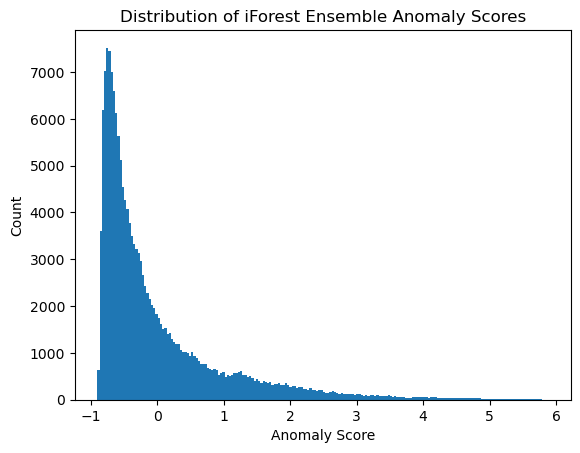

In [21]:
# I plot the distribution of the ensemble iForest scores to check whether there is a natural break I can pick a threshold from.
# The distribution decays smoothly from the peak near 0 out through the tail, with no point where the density visibly drops off,
# so a threshold cannot really be read off this plot by eye.
plt.hist(iforest_ensemble_scores, bins='auto')
plt.title('Distribution of iForest Ensemble Anomaly Scores')
plt.xlabel('Anomaly Score')
plt.ylabel('Count')
plt.show()

In [22]:
# Since the score distribution does not show a visible break, I fall back on the contamination assumption directly instead
# of picking a threshold by eye. A threshold at the 95th percentile of the ensemble scores corresponds to the 5 percent
# contamination rate I used to build the ensemble, so I use that percentile as the threshold rather than a value chosen from the plot.
iforest_threshold = np.percentile(iforest_ensemble_scores, 95)
iforest_pred = (iforest_ensemble_scores >= iforest_threshold).astype(int)

print("The threshold at the 95th percentile of the ensemble scores is", iforest_threshold)

The threshold at the 95th percentile of the ensemble scores is 2.130283074699664


In [23]:
feature_list = ['total_payment_ratio_state_drg',
    'total_payment_median_ratio_state_drg',
    'discharge_median_ratio_state_drg',
    'total_payment_median_ratio_region_drg',
    'provider_high_total_payment_count'
]

def descriptive_stat_threshold(df, pred_score, threshold):
    # This function splits the dataset into Normal and Outlier groups using the given threshold,
    # then returns a summary table showing the count, percentage, and average
    # feature value for each group.
    df = pd.DataFrame(df)
    df.columns = feature_list
    df['Anomaly_Score'] = pred_score
    df['Group'] = np.where(df['Anomaly_Score'] < threshold, 'Normal', 'Outlier')

    cnt = df.groupby('Group')['Anomaly_Score'].count().reset_index().rename(columns={'Anomaly_Score':'Count'})
    cnt['Count %'] = (cnt['Count'] / cnt['Count'].sum()) * 100
    stat = df.groupby('Group').mean().round(2).reset_index()
    stat = cnt.merge(stat, left_on='Group', right_on='Group')
    return stat

descriptive_stat_threshold(feature_matrix, iforest_ensemble_scores, iforest_threshold)

,Group,Count,Count %,total_payment_ratio_state_drg,total_payment_median_ratio_state_drg,discharge_median_ratio_state_drg,total_payment_median_ratio_region_drg,provider_high_total_payment_count,Anomaly_Score
0,Normal,154911,94.99954,0.98,1.02,1.22,1.02,0.02,-0.16
1,Outlier,8154,5.00046,1.47,1.58,1.99,1.43,2.73,3.13


### Where Are the Potentially Anomalous Providers?

In [24]:
# I attach the iForest ensemble scores and labels back to the provider level data.
df_iforest = feature_df.copy()
df_iforest['iforest_score'] = iforest_ensemble_scores
df_iforest['iforest_label'] = iforest_pred

# I sort the flagged records by anomaly score so the most extreme cases show up first.
top_iforest = df_iforest[df_iforest['iforest_label'] == 1].sort_values('iforest_score', ascending=False)

display_cols = [
    'Provider_Name', 'Provider_State', 'DRG', 'Average_Total_Payments', 'Total_Discharges',
    'total_payment_ratio_state_drg', 'total_payment_median_ratio_state_drg',
    'discharge_median_ratio_state_drg', 'total_payment_median_ratio_region_drg',
    'provider_high_total_payment_count', 'iforest_score'
]

print('Total flagged by iForest is', df_iforest['iforest_label'].sum(), 'which is', round(df_iforest['iforest_label'].mean()*100, 2), 'percent of all records')
top_iforest[display_cols].head(20)

Total flagged by iForest is 8154 which is 5.0 percent of all records


,Provider_Name,Provider_State,DRG,Average_Total_Payments,Total_Discharges,total_payment_ratio_state_drg,total_payment_median_ratio_state_drg,discharge_median_ratio_state_drg,total_payment_median_ratio_region_drg,provider_high_total_payment_count,iforest_score
145894,"JOHNS HOPKINS HOSPITAL, THE",MD,699 - OTHER KIDNEY & URINARY TRACT DIAGNOSES W CC,28205.34,111,3.207142,3.645043,5.842105,3.594488,20,5.881399
144802,JACKSON MEMORIAL HOSPITAL,FL,698 - OTHER KIDNEY & URINARY TRACT DIAGNOSES W...,25901.75,57,2.578948,2.836897,3.352941,2.347781,49,5.839225
145683,JACKSON MEMORIAL HOSPITAL,FL,699 - OTHER KIDNEY & URINARY TRACT DIAGNOSES W CC,15025.13,96,2.386206,2.582958,5.647059,2.017776,49,5.838168
154474,JACKSON MEMORIAL HOSPITAL,FL,885 - PSYCHOSES,13430.02,356,2.129390,2.334582,13.185185,1.808701,49,5.823237
135862,UNIVERSITY OF TEXAS MEDICAL BRANCH GAL,TX,682 - RENAL FAILURE W MCC,29137.36,19,2.654579,2.850700,0.500000,2.753045,53,5.772362
145004,"JOHNS HOPKINS HOSPITAL, THE",MD,698 - OTHER KIDNEY & URINARY TRACT DIAGNOSES W...,43860.44,56,2.817589,3.532489,3.500000,3.114517,20,5.769166
149538,UNIVERSITY OF TEXAS MEDICAL BRANCH GAL,TX,812 - RED BLOOD CELL DISORDERS W/O MCC,12992.29,65,2.462788,2.632555,2.131148,2.611201,53,5.753469
157174,UNIVERSITY OF TEXAS MEDICAL BRANCH GAL,TX,872 - SEPTICEMIA OR SEVERE SEPSIS W/O MV 96+ H...,20243.22,18,2.727868,2.898290,0.580645,2.872848,53,5.753416
5876,UNIVERSITY OF TEXAS MEDICAL BRANCH GAL,TX,065 - INTRACRANIAL HEMORRHAGE OR CEREBRAL INFA...,21790.40,25,2.882244,3.059255,0.735294,2.982298,53,5.752039
111131,UNIVERSITY OF TEXAS MEDICAL BRANCH GAL,TX,469 - MAJOR JOINT REPLACEMENT OR REATTACHMENT ...,61342.23,13,2.818446,2.964190,0.764706,2.687759,53,5.750150


### Business Insight

iForest flagged 8,154 provider DRG records, which is exactly 5 percent of all records in the dataset, matching the contamination assumption used to build the ensemble.

The feature comparison table shows that the repeated high payment count is by far the strongest driver of these flags. Flagged records average about 2.73 on this feature compared to only 0.02 for normal records, which works out to a ratio of roughly 114. This means iForest is mainly picking out providers whose elevated payments repeat across many DRG categories rather than providers with just one unusual record. The discharge ratio comes in as the second strongest signal, with flagged records averaging about 1.63 times the normal group. This is notably higher than the payment ratio features, which sit closer to 1.4 to 1.5 times normal. So unlike a method that leans almost entirely on payment history, iForest is also weighing patient volume fairly heavily, which fits with how the algorithm works. Since it isolates records through random splits across all features at once, it naturally picks up on records that stand out because two or three features are moderately unusual together, not only records where one feature is extremely unusual on its own.

New York, California, and Illinois are the states that show up most often among the flagged records, followed closely by Texas, Pennsylvania, and Florida. Among DRGs, sepsis, digestive disorders, and heart failure categories appear most frequently, which are the same high volume, high cost case types that showed up under the earlier methods in this notebook. The specific providers at the top of the flagged list, including Johns Hopkins Hospital, Jackson Memorial Hospital, and the University of Texas Medical Branch, are large academic and referral centers, so the pattern iForest is finding may partly reflect that these hospitals treat more complicated patients rather than pure billing anomalies.

Given this, the most useful next step would be to review the flagged records at these specific hospitals within the DRG categories above, paying close attention to whether the elevated discharge ratio and payment ratio are explained by how complicated the patients are or point to something that needs further audit.

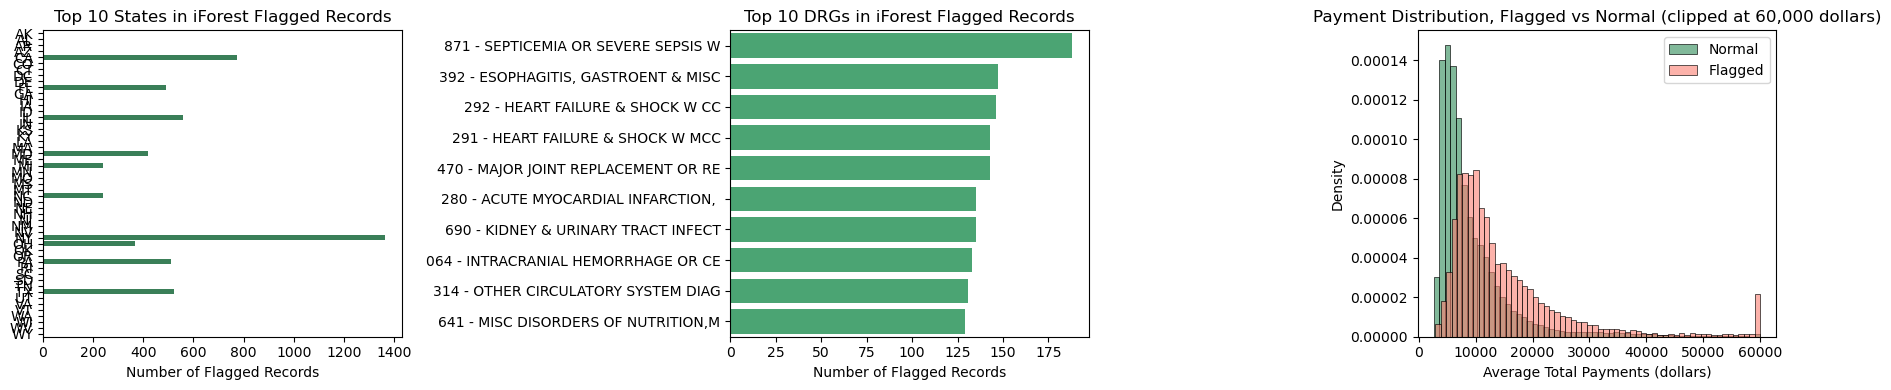

Average feature values for flagged versus normal records under iForest
                              Feature  Normal Avg  Flagged Avg  Ratio (Flagged/Normal)
        total_payment_ratio_state_drg       0.975        1.474                    1.51
 total_payment_median_ratio_state_drg       1.023        1.576                    1.54
     discharge_median_ratio_state_drg       1.222        1.992                    1.63
total_payment_median_ratio_region_drg       1.016        1.429                    1.41
    provider_high_total_payment_count       0.024        2.730                  113.75


In [25]:
# I separate the flagged and normal records so I can compare them directly.
iforest_outliers = df_iforest[df_iforest['iforest_label'] == 1]
iforest_normal   = df_iforest[df_iforest['iforest_label'] == 0]

fig, axes = plt.subplots(1, 3, figsize=(18, 4))

# I look at the top 10 states among the flagged records.
top_states_iforest = (iforest_outliers['Provider_State']
                       .value_counts().head(10).reset_index())
top_states_iforest.columns = ['Provider_State', 'Count']
sns.barplot(x='Count', y='Provider_State', data=top_states_iforest, ax=axes[0], color='seagreen')
axes[0].set_title('Top 10 States in iForest Flagged Records')
axes[0].set_xlabel('Number of Flagged Records')
axes[0].set_ylabel('')

# I look at the top 10 DRGs among the flagged records.
top_drgs_iforest = (iforest_outliers['DRG']
                     .value_counts().head(10).reset_index())
top_drgs_iforest.columns = ['DRG', 'Count']
top_drgs_iforest['DRG'] = top_drgs_iforest['DRG'].astype(str).str[:35]
sns.barplot(x='Count', y='DRG', data=top_drgs_iforest, ax=axes[1], color='mediumseagreen')
axes[1].set_title('Top 10 DRGs in iForest Flagged Records')
axes[1].set_xlabel('Number of Flagged Records')
axes[1].set_ylabel('')

# I compare the payment distribution between flagged and normal records.
sns.histplot(iforest_normal['Average_Total_Payments'].clip(upper=60000), bins=60, ax=axes[2],
             color='seagreen', label='Normal', alpha=0.6, stat='density')
sns.histplot(iforest_outliers['Average_Total_Payments'].clip(upper=60000), bins=60, ax=axes[2],
             color='salmon', label='Flagged', alpha=0.6, stat='density')
axes[2].set_title('Payment Distribution, Flagged vs Normal (clipped at 60,000 dollars)')
axes[2].set_xlabel('Average Total Payments (dollars)')
axes[2].legend()

plt.tight_layout()
plt.show()

# I compute the average feature values for the flagged group versus the normal group.
comparison_iforest = pd.DataFrame({
    'Feature'       : feature_cols,
    'Normal Avg'    : iforest_normal[feature_cols].mean().round(3).values,
    'Flagged Avg'   : iforest_outliers[feature_cols].mean().round(3).values
})
comparison_iforest['Ratio (Flagged/Normal)'] = (comparison_iforest['Flagged Avg'] / comparison_iforest['Normal Avg']).round(2)
print('Average feature values for flagged versus normal records under iForest')
print(comparison_iforest.to_string(index=False))

## Section 3: Autoencoder

### What is an Autoencoder?

An autoencoder is a neural network trained to replicate its own input as its output. Most neural networks are trained under supervised learning, where the target values come from labeled data, but an autoencoder is trained under unsupervised learning instead, since its target values are simply the same input values it was given, so no separate labels are needed. Because the output is just a copy of the input, the real value of an autoencoder does not come from the output layer at all, it comes from the hidden layers in between.

For that to be useful, the hidden layers need fewer neurons than the input layer. With fewer neurons available, the network cannot just pass every value straight through, it has to compress the feature matrix down into a smaller representation and then rebuild it back to the original number of features, which forces it to keep only the most important patterns in the data and let go of the rest. If the hidden layers had as many neurons as the input layer, or more, the network would have enough room to copy the input exactly, noise included, without ever being forced to learn which patterns actually matter.

A normal record fits the patterns the network has learned, so it compresses and rebuilds cleanly and produces a small error. A record that does not fit those patterns is harder to compress and rebuild accurately, so it produces a larger reconstruction error. That reconstruction error becomes the anomaly score, and records with the highest error are treated as the most likely anomalies.

### Model

For the model, I first fit a single Autoencoder as a quick initial check, using its own built in threshold from the contamination rate. From there I build a more stable score by fitting three Autoencoders with different hidden layer structures, one small and shallow, one medium, and one deeper with more layers, and then averaging their normalized scores. This gives the ensemble a similar kind of diversity to what varying n_estimators gave the iForest ensemble, except here the diversity comes from network depth and width instead of the number of trees. Unlike iForest, the ensemble score distribution here does not show a visible break, so instead of picking a threshold from the histogram, I use the 95th percentile of the ensemble scores, which lines up with the 5 percent contamination rate I used to build the ensemble.

In [26]:
# I fit a single Autoencoder first as a quick initial check, using its own built in threshold from the contamination rate.
autoencoder = AutoEncoder(contamination=0.05, hidden_neuron_list=[2, 2], batch_size=1024, random_state=42, verbose=0)
autoencoder.fit(feature_matrix)

autoencoder_train_scores = autoencoder.decision_function(feature_matrix)
autoencoder_train_pred = autoencoder.predict(feature_matrix)

print("The threshold for the defined contamination rate is", autoencoder.threshold_)
print("The training data flags the following counts", count_stat(autoencoder_train_pred))

The threshold for the defined contamination rate is 2.7350552
The training data flags the following counts {np.int64(0): np.int64(154911), np.int64(1): np.int64(8154)}


### Anomaly Count and Percentage

In [27]:
# A single Autoencoder fit can depend a lot on the specific architecture chosen, so I build a more
# stable score by fitting three Autoencoders with different hidden layer structures, one small and shallow,
# one medium, and one deeper with more layers, and then averaging their normalized scores. This follows the
# same ensemble idea I used for iForest, except the diversity here comes from network depth and width instead
# of the number of trees. I also use a larger batch size than the default so training finishes in a
# reasonable amount of time given how many rows are in this dataset.
autoencoder1 = AutoEncoder(contamination=0.05, hidden_neuron_list=[2, 2], batch_size=1024, random_state=42, verbose=0)
autoencoder2 = AutoEncoder(contamination=0.05, hidden_neuron_list=[10, 2, 10], batch_size=1024, random_state=42, verbose=0)
autoencoder3 = AutoEncoder(contamination=0.05, hidden_neuron_list=[15, 10, 2, 10, 15], batch_size=1024, random_state=42, verbose=0)

train_scores = np.zeros([feature_matrix.shape[0], 3])
autoencoder1.fit(feature_matrix)
autoencoder2.fit(feature_matrix)
autoencoder3.fit(feature_matrix)

train_scores[:, 0] = autoencoder1.decision_function(feature_matrix)
train_scores[:, 1] = autoencoder2.decision_function(feature_matrix)
train_scores[:, 2] = autoencoder3.decision_function(feature_matrix)

# The decision scores need to be normalized before they can be combined.
train_scores_norm = standardizer(train_scores)

# I combine the scores by taking the average across the three architectures, which gives a single, more stable score for each record.
autoencoder_ensemble_scores = average(train_scores_norm)

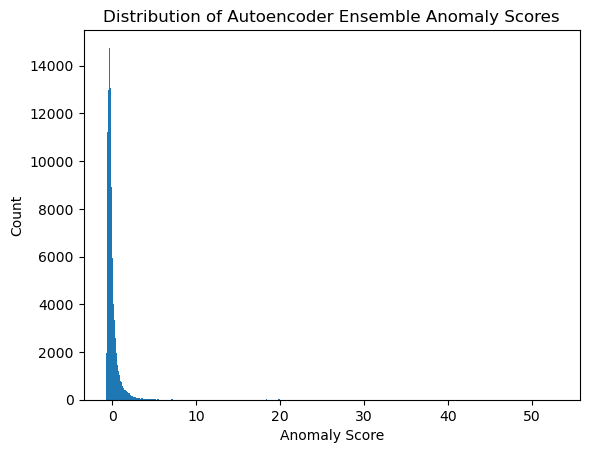

In [28]:
# I plot the distribution of the ensemble Autoencoder scores to check whether there is a natural break I can pick a threshold from.
# The distribution is heavily right skewed, with almost all records packed near 0 and a long thin tail stretching out past 50.
# Unlike iForest, there is no point where the density visibly drops off, the tail just decays smoothly the whole way, which is
# the same situation I ran into with PCA earlier in this notebook.
plt.hist(autoencoder_ensemble_scores, bins='auto')
plt.title('Distribution of Autoencoder Ensemble Anomaly Scores')
plt.xlabel('Anomaly Score')
plt.ylabel('Count')
plt.show()

In [29]:
# Since the score distribution does not show a visible break, I fall back on the contamination assumption directly instead
# of picking a threshold by eye. A threshold at the 95th percentile of the ensemble scores corresponds to the 5 percent
# contamination rate I used to build the ensemble, so I use that percentile as the threshold rather than a value chosen from the plot.
autoencoder_threshold = np.percentile(autoencoder_ensemble_scores, 95)
autoencoder_pred = (autoencoder_ensemble_scores >= autoencoder_threshold).astype(int)

print("The threshold at the 95th percentile of the ensemble scores is", autoencoder_threshold)

descriptive_stat_threshold(feature_matrix, autoencoder_ensemble_scores, autoencoder_threshold)

The threshold at the 95th percentile of the ensemble scores is 1.2702822461545475


,Group,Count,Count %,total_payment_ratio_state_drg,total_payment_median_ratio_state_drg,discharge_median_ratio_state_drg,total_payment_median_ratio_region_drg,provider_high_total_payment_count,Anomaly_Score
0,Normal,154911,94.99954,0.98,1.03,1.17,1.02,0.04,-0.15
1,Outlier,8154,5.00046,1.42,1.52,2.88,1.39,2.34,2.77


### Where Are the Potentially Anomalous Providers?

In [30]:
# I attach the Autoencoder ensemble scores and labels back to the provider level data.
df_autoencoder = feature_df.copy()
df_autoencoder['autoencoder_score'] = autoencoder_ensemble_scores
df_autoencoder['autoencoder_label'] = autoencoder_pred

# I sort the flagged records by anomaly score so the most extreme cases show up first.
top_autoencoder = df_autoencoder[df_autoencoder['autoencoder_label'] == 1].sort_values('autoencoder_score', ascending=False)

display_cols = [
    'Provider_Name', 'Provider_State', 'DRG', 'Average_Total_Payments', 'Total_Discharges',
    'total_payment_ratio_state_drg', 'total_payment_median_ratio_state_drg',
    'discharge_median_ratio_state_drg', 'total_payment_median_ratio_region_drg',
    'provider_high_total_payment_count', 'autoencoder_score'
]

print('Total flagged by Autoencoder is', df_autoencoder['autoencoder_label'].sum(), 'which is', round(df_autoencoder['autoencoder_label'].mean()*100, 2), 'percent of all records')
top_autoencoder[display_cols].head(20)

Total flagged by Autoencoder is 8154 which is 5.0 percent of all records


,Provider_Name,Provider_State,DRG,Average_Total_Payments,Total_Discharges,total_payment_ratio_state_drg,total_payment_median_ratio_state_drg,discharge_median_ratio_state_drg,total_payment_median_ratio_region_drg,provider_high_total_payment_count,autoencoder_score
158518,ADCARE HOSPITAL OF WORCESTER INC,MA,897 - ALCOHOL/DRUG ABUSE OR DEPENDENCE W/O REH...,4967.56,1571,0.962335,1.020657,71.409091,1.015292,0,53.017843
38923,STURDY MEMORIAL HOSPITAL,MA,203 - BRONCHITIS & ASTHMA W/O CC/MCC,41482.09,11,7.263177,9.338775,0.647059,8.618473,1,39.425302
20388,ST JOSEPH MEDICAL CENTER,PA,189 - PULMONARY EDEMA & RESPIRATORY FAILURE,72797.93,143,7.857934,9.150067,5.107143,7.883990,1,38.274005
154666,NORTH SHORE MEDICAL CENTER,FL,885 - PSYCHOSES,6736.67,1328,1.068129,1.171056,49.185185,0.907268,0,35.911248
112969,HOSPITAL FOR SPECIAL SURGERY,NY,470 - MAJOR JOINT REPLACEMENT OR REATTACHMENT ...,19023.70,3383,1.134971,1.235385,46.342466,0.822754,0,33.734585
157643,LARKIN COMMUNITY HOSPITAL,FL,885 - PSYCHOSES,7521.30,1116,1.192536,1.307451,41.333333,1.012938,0,29.852368
153786,UNIVERSITY OF MIAMI HOSPITAL,FL,885 - PSYCHOSES,7109.27,1113,1.127207,1.235826,41.222222,0.957448,0,29.773715
49145,OVERLAKE HOSPITAL MEDICAL CENTER,WA,249 - PERC CARDIOVASC PROC W NON-DRUG-ELUTING ...,84499.26,23,4.748859,6.575751,1.045455,6.736009,1,26.940253
162713,CANCER TREATMENT CENTERS OF AMERICA,PA,948 - SIGNS & SYMPTOMS W/O MCC,28968.20,24,5.771927,6.471822,1.043478,5.989806,2,26.002313
47957,AVERA HEART HOSPITAL OF SOUTH DAKOTA LLC,SD,247 - PERC CARDIOVASC PROC W DRUG-ELUTING STEN...,83484.14,121,2.678654,5.720311,1.052174,6.728023,1,24.535180


### Business Insight

Autoencoder flagged 8,154 provider DRG records, which is almost exactly 5 percent of all records in the dataset, matching the contamination assumption used to build the ensemble very closely.

The feature comparison table shows the same overall pattern as iForest, with the repeated high payment count as the clear strongest driver, averaging about 53 times higher in flagged records than in normal ones. What stands out here is the discharge ratio, which comes in noticeably stronger under Autoencoder than it did under iForest. Flagged records average about 2.34 times the normal group on this feature, compared to only about 1.64 times under iForest. This suggests Autoencoder is weighing patient volume more heavily relative to payment history than iForest does, which fits with how the two methods work differently. Autoencoder judges a record by how well the whole feature vector can be compressed and rebuilt at once, so a record that is only moderately unusual on two features together, such as discharge volume and payment level, can end up with a large reconstruction error even if neither feature alone looks extreme on its own.

New York, California, and Texas are the states that show up most often among the flagged records, followed by Pennsylvania and Florida, largely the same states that came up under iForest. Among DRGs, major joint replacement and sepsis are again the most common, along with digestive disorders and heart failure categories. The specific providers at the top of the flagged list look different from what iForest surfaced, though. Instead of large academic centers, the highest scoring providers here include smaller and more specialized hospitals such as AdCare Hospital of Worcester and Sturdy Memorial Hospital. This is a useful contrast with iForest, since it suggests Autoencoder may be more sensitive to smaller providers whose billing pattern looks unusual precisely because they treat a narrower or more specialized set of cases, rather than the more complicated patients that seemed to explain some of what iForest found.

Given this, it would be worth reviewing the flagged records at these specific hospitals to see whether their elevated discharge ratio and payment ratio reflect a narrow specialty focus or something that needs further audit, and comparing this list directly against the providers iForest flagged to see how much the two methods actually agree on.

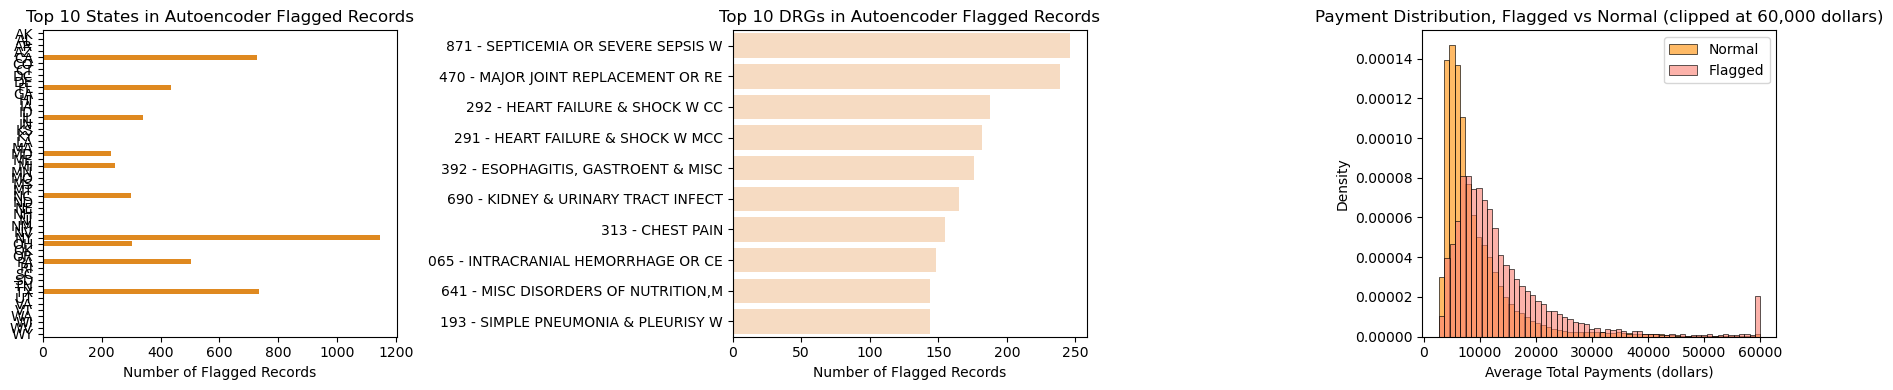

Average feature values for flagged versus normal records under Autoencoder
                              Feature  Normal Avg  Flagged Avg  Ratio (Flagged/Normal)
        total_payment_ratio_state_drg       0.978        1.421                    1.45
 total_payment_median_ratio_state_drg       1.026        1.517                    1.48
     discharge_median_ratio_state_drg       1.175        2.882                    2.45
total_payment_median_ratio_region_drg       1.018        1.392                    1.37
    provider_high_total_payment_count       0.045        2.342                   52.04


In [31]:
# I separate the flagged and normal records so I can compare them directly.
autoencoder_outliers = df_autoencoder[df_autoencoder['autoencoder_label'] == 1]
autoencoder_normal   = df_autoencoder[df_autoencoder['autoencoder_label'] == 0]

fig, axes = plt.subplots(1, 3, figsize=(18, 4))

# I look at the top 10 states among the flagged records.
top_states_autoencoder = (autoencoder_outliers['Provider_State']
                           .value_counts().head(10).reset_index())
top_states_autoencoder.columns = ['Provider_State', 'Count']
sns.barplot(x='Count', y='Provider_State', data=top_states_autoencoder, ax=axes[0], color='darkorange')
axes[0].set_title('Top 10 States in Autoencoder Flagged Records')
axes[0].set_xlabel('Number of Flagged Records')
axes[0].set_ylabel('')

# I look at the top 10 DRGs among the flagged records.
top_drgs_autoencoder = (autoencoder_outliers['DRG']
                         .value_counts().head(10).reset_index())
top_drgs_autoencoder.columns = ['DRG', 'Count']
top_drgs_autoencoder['DRG'] = top_drgs_autoencoder['DRG'].astype(str).str[:35]
sns.barplot(x='Count', y='DRG', data=top_drgs_autoencoder, ax=axes[1], color='peachpuff')
axes[1].set_title('Top 10 DRGs in Autoencoder Flagged Records')
axes[1].set_xlabel('Number of Flagged Records')
axes[1].set_ylabel('')

# I compare the payment distribution between flagged and normal records.
sns.histplot(autoencoder_normal['Average_Total_Payments'].clip(upper=60000), bins=60, ax=axes[2],
             color='darkorange', label='Normal', alpha=0.6, stat='density')
sns.histplot(autoencoder_outliers['Average_Total_Payments'].clip(upper=60000), bins=60, ax=axes[2],
             color='salmon', label='Flagged', alpha=0.6, stat='density')
axes[2].set_title('Payment Distribution, Flagged vs Normal (clipped at 60,000 dollars)')
axes[2].set_xlabel('Average Total Payments (dollars)')
axes[2].legend()

plt.tight_layout()
plt.show()

# I compute the average feature values for the flagged group versus the normal group.
comparison_autoencoder = pd.DataFrame({
    'Feature'       : feature_cols,
    'Normal Avg'    : autoencoder_normal[feature_cols].mean().round(3).values,
    'Flagged Avg'   : autoencoder_outliers[feature_cols].mean().round(3).values
})
comparison_autoencoder['Ratio (Flagged/Normal)'] = (comparison_autoencoder['Flagged Avg'] / comparison_autoencoder['Normal Avg']).round(2)
print('Average feature values for flagged versus normal records under Autoencoder')
print(comparison_autoencoder.to_string(index=False))

## Section 4: Summary and Comparison of iForest and Autoencoder

This section brings together the results from iForest and Autoencoder to see what each method identified and how much they agree with each other. Since the two methods work in very different ways, one through isolating records with random splits and the other through how well a record can be compressed and rebuilt, comparing their outputs shows whether they are catching the same anomalies or picking up on different kinds of unusual billing behavior. Records flagged by both methods at once are the strongest candidates for further review, since they look unusual under two very different approaches.

In [32]:
# Summary table comparing the threshold, flagged count, and primary driver for each method
summary = pd.DataFrame({
    'Method'           : ['iForest', 'Autoencoder'],
    'Threshold'        : [round(iforest_threshold, 3), round(autoencoder_threshold, 3)],
    'Threshold Source' : ['95th percentile of ensemble scores', '95th percentile of ensemble scores'],
    'Flagged Count'    : [df_iforest['iforest_label'].sum(), df_autoencoder['autoencoder_label'].sum()],
    'Flagged Percent'  : [round(df_iforest['iforest_label'].mean()*100, 2), round(df_autoencoder['autoencoder_label'].mean()*100, 2)],
    'Primary Driver'   : ['Repeated high payment count, with discharge ratio as a secondary signal',
                          'Repeated high payment count, with discharge ratio weighted even more heavily']
})
print(summary.to_string(index=False))

     Method  Threshold                   Threshold Source  Flagged Count  Flagged Percent                                                               Primary Driver
    iForest       2.13 95th percentile of ensemble scores           8154              5.0      Repeated high payment count, with discharge ratio as a secondary signal
Autoencoder       1.27 95th percentile of ensemble scores           8154              5.0 Repeated high payment count, with discharge ratio weighted even more heavily


Overlap breakdown
iForest only 2305
Autoencoder only 2305
Both methods 5849
Total unique flagged 10459


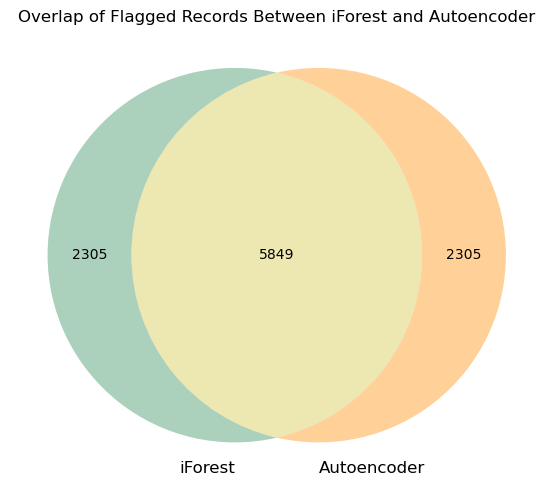

In [33]:
# Compute the overlap between the two flagged sets
iforest_idx = set(df_iforest[df_iforest['iforest_label'] == 1].index)
autoencoder_idx = set(df_autoencoder[df_autoencoder['autoencoder_label'] == 1].index)

only_iforest = len(iforest_idx - autoencoder_idx)
only_autoencoder = len(autoencoder_idx - iforest_idx)
both_methods = len(iforest_idx & autoencoder_idx)

print("Overlap breakdown")
print("iForest only", only_iforest)
print("Autoencoder only", only_autoencoder)
print("Both methods", both_methods)
print("Total unique flagged", only_iforest + only_autoencoder + both_methods)

# Venn diagram, falls back to a bar chart if matplotlib_venn is not installed
try:
    from matplotlib_venn import venn2
    plt.figure(figsize=(7, 5))
    venn2(
        subsets=(only_iforest, only_autoencoder, both_methods),
        set_labels=('iForest', 'Autoencoder'),
        set_colors=('seagreen', 'darkorange')
    )
    plt.title('Overlap of Flagged Records Between iForest and Autoencoder')
    plt.tight_layout()
    plt.show()
except ImportError:
    labels = ['iForest only', 'Autoencoder only', 'Both methods']
    values = [only_iforest, only_autoencoder, both_methods]
    plt.figure(figsize=(8, 4))
    sns.barplot(x=labels, y=values, color='seagreen')
    plt.title('Overlap of Flagged Records Between iForest and Autoencoder')
    plt.xlabel('Group')
    plt.ylabel('Number of Records')
    plt.tight_layout()
    plt.show()

### Consensus Anomalies, Flagged by Both Methods

Records flagged by both iForest and Autoencoder are the strongest anomaly candidates in this dataset, since they look unusual under two very different detection approaches. The table below shows the top consensus records sorted by the Autoencoder score, along with their key feature values and individual scores from each method.

In [34]:
# Pull out records flagged by both methods
consensus_idx = iforest_idx & autoencoder_idx
df_consensus = feature_df.loc[list(consensus_idx)].copy()
df_consensus['iforest_score'] = df_iforest.loc[list(consensus_idx), 'iforest_score'].values
df_consensus['autoencoder_score'] = df_autoencoder.loc[list(consensus_idx), 'autoencoder_score'].values

print("Records flagged by both methods", len(df_consensus))

display_cols = [
    'Provider_Name', 'Provider_State', 'DRG', 'Average_Total_Payments', 'Total_Discharges',
    'discharge_median_ratio_state_drg', 'total_payment_median_ratio_state_drg',
    'provider_high_total_payment_count',
    'iforest_score', 'autoencoder_score'
]
df_consensus.sort_values('autoencoder_score', ascending=False)[display_cols].head(20)

Records flagged by both methods 5849


,Provider_Name,Provider_State,DRG,Average_Total_Payments,Total_Discharges,discharge_median_ratio_state_drg,total_payment_median_ratio_state_drg,provider_high_total_payment_count,iforest_score,autoencoder_score
158518,ADCARE HOSPITAL OF WORCESTER INC,MA,897 - ALCOHOL/DRUG ABUSE OR DEPENDENCE W/O REH...,4967.56,1571,71.409091,1.020657,0,2.315374,53.017843
38923,STURDY MEMORIAL HOSPITAL,MA,203 - BRONCHITIS & ASTHMA W/O CC/MCC,41482.09,11,0.647059,9.338775,1,4.890293,39.425302
20388,ST JOSEPH MEDICAL CENTER,PA,189 - PULMONARY EDEMA & RESPIRATORY FAILURE,72797.93,143,5.107143,9.150067,1,5.239934,38.274005
154666,NORTH SHORE MEDICAL CENTER,FL,885 - PSYCHOSES,6736.67,1328,49.185185,1.171056,0,2.818253,35.911248
112969,HOSPITAL FOR SPECIAL SURGERY,NY,470 - MAJOR JOINT REPLACEMENT OR REATTACHMENT ...,19023.70,3383,46.342466,1.235385,0,3.220154,33.734585
157643,LARKIN COMMUNITY HOSPITAL,FL,885 - PSYCHOSES,7521.30,1116,41.333333,1.307451,0,3.021066,29.852368
153786,UNIVERSITY OF MIAMI HOSPITAL,FL,885 - PSYCHOSES,7109.27,1113,41.222222,1.235826,0,2.957988,29.773715
49145,OVERLAKE HOSPITAL MEDICAL CENTER,WA,249 - PERC CARDIOVASC PROC W NON-DRUG-ELUTING ...,84499.26,23,1.045455,6.575751,1,4.861164,26.940253
162713,CANCER TREATMENT CENTERS OF AMERICA,PA,948 - SIGNS & SYMPTOMS W/O MCC,28968.20,24,1.043478,6.471822,2,4.985172,26.002313
47957,AVERA HEART HOSPITAL OF SOUTH DAKOTA LLC,SD,247 - PERC CARDIOVASC PROC W DRUG-ELUTING STEN...,83484.14,121,1.052174,5.720311,1,4.853582,24.535180


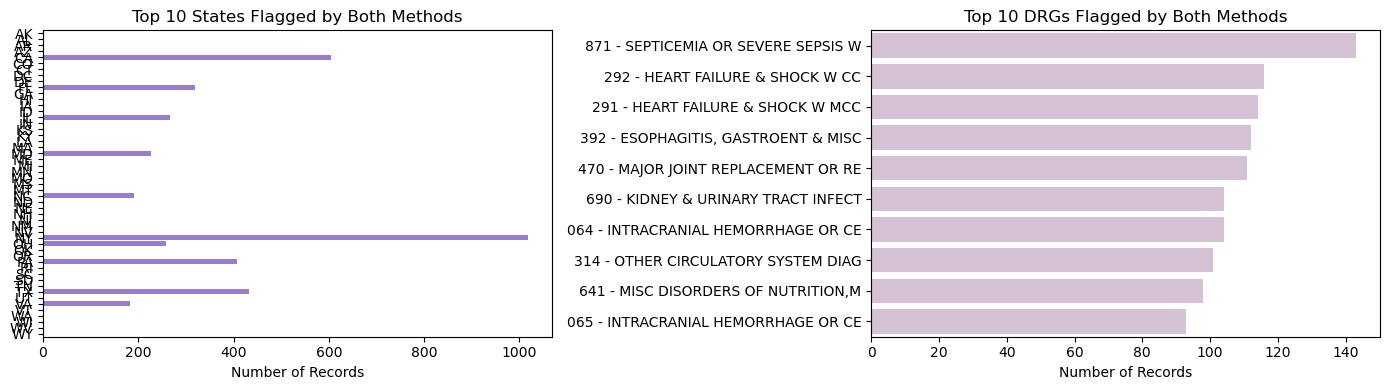

Feature averages for consensus flagged versus normal records
                              Feature  Normal Avg  Consensus Avg  Ratio
        total_payment_ratio_state_drg       0.974          1.574   1.62
 total_payment_median_ratio_state_drg       1.022          1.687   1.65
     discharge_median_ratio_state_drg       1.170          2.199   1.88
total_payment_median_ratio_region_drg       1.015          1.519   1.50
    provider_high_total_payment_count       0.024          3.265 136.04


In [35]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

# Top states among the consensus flagged records
top_states_con = df_consensus['Provider_State'].value_counts().head(10).reset_index()
top_states_con.columns = ['Provider_State', 'Count']
sns.barplot(x='Count', y='Provider_State', data=top_states_con, ax=axes[0], color='mediumpurple')
axes[0].set_title('Top 10 States Flagged by Both Methods')
axes[0].set_xlabel('Number of Records')
axes[0].set_ylabel('')

# Top DRGs among the consensus flagged records
top_drgs_con = df_consensus['DRG'].value_counts().head(10).reset_index()
top_drgs_con.columns = ['DRG', 'Count']
top_drgs_con['DRG'] = top_drgs_con['DRG'].astype(str).str[:35]
sns.barplot(x='Count', y='DRG', data=top_drgs_con, ax=axes[1], color='thistle')
axes[1].set_title('Top 10 DRGs Flagged by Both Methods')
axes[1].set_xlabel('Number of Records')
axes[1].set_ylabel('')

plt.tight_layout()
plt.show()

# Feature averages for consensus records versus records not flagged by either method
normal_idx = set(feature_df.index) - iforest_idx - autoencoder_idx
df_normal_both = feature_df.loc[list(normal_idx)]

comparison_con = pd.DataFrame({
    'Feature'      : feature_cols,
    'Normal Avg'   : df_normal_both[feature_cols].mean().round(3).values,
    'Consensus Avg': df_consensus[feature_cols].mean().round(3).values
})
comparison_con['Ratio'] = (comparison_con['Consensus Avg'] / comparison_con['Normal Avg']).round(2)
print("Feature averages for consensus flagged versus normal records")
print(comparison_con.to_string(index=False))

### Overall Business Insight

iForest and Autoencoder agree on a large share of what they flag. Of the 8,154 records each method flags, 5,849 are flagged by both, which is about 71.7 percent of either method's list. This level of agreement is meaningful given how differently the two methods work, one through isolating records with random splits and the other through reconstruction error from a compressed representation, and it suggests that the anomalies in this dataset are not just something one algorithm happens to pick up but a real pattern that shows up under more than one method.

The records both methods agree on look like an intensified version of what iForest found on its own. The repeated high payment count is again the dominant driver, now averaging about 136 times higher in the consensus group than in records neither method flags, even higher than either method's own ratio on its own. The discharge ratio is also more pronounced here, at about 1.88 times normal, sitting between iForest's 1.63 and Autoencoder's 2.34. This makes sense given that Autoencoder tends to weigh patient volume more heavily than iForest does, so records that satisfy both methods tend to be unusual on payment history and volume at the same time, not just one or the other.

The roughly 2,300 records flagged by only one method are worth treating differently from the consensus group. Records iForest catches on its own but Autoencoder does not are likely cases where the anomaly is driven by an unusual combination of features that a random split can isolate quickly but does not create enough reconstruction error to stand out to the Autoencoder. Records Autoencoder catches on its own but iForest does not are likely the opposite, cases where several features are each only mildly unusual, which is exactly the kind of pattern reconstruction error is more sensitive to than splitting the data apart the way iForest does.

The same states and DRG categories keep showing up across every method in this notebook, with New York, California, and Texas among the states, and sepsis, heart failure, and major joint replacement among the DRGs. For a business audience, the most actionable takeaway is to prioritize the 5,849 consensus records first, since two very different methods agreeing on the same providers is a stronger signal than either method's list on its own, and then treat the method specific lists as a secondary, lower confidence set worth a lighter review rather than an immediate audit.